# 05 - Chronological Model Training, Validation Selection, and Protected Test Evaluation


## 1. Environment Setup, Chronological Splits, and Multi-Metric Evaluation Function


In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge, TweedieRegressor
from sklearn.metrics import (
    mean_absolute_error,
    median_absolute_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.svm import SVR

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

# Resolve portable relative paths
PROJECT_ROOT = Path("..") if Path("data/processed/icnf_sgif").exists() is False and Path("../data/processed/icnf_sgif").exists() else Path(".")
DATA_DIR = Path("data/processed/icnf_sgif")
TABLES_DIR = Path("reports/tables/icnf_sgif")
FIGURES_DIR = Path("reports/figures/icnf_sgif")
MODELS_DIR = Path("models")
UCI_CLEANED_PATH = (
    Path("../02_ORIGINAL_UCI_EVIDENCE/Dataset/cleaned_forest_fires.csv")
    if Path("../02_ORIGINAL_UCI_EVIDENCE/Dataset/cleaned_forest_fires.csv").exists()
    else Path("02_ORIGINAL_UCI_EVIDENCE/Dataset/cleaned_forest_fires.csv")
)

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)


def compute_evaluation_metrics(y_true_ha, y_pred_ha):
    """Compute multi-metric regression diagnostics in both log1p space and raw hectares."""
    y_true = np.asarray(y_true_ha, dtype=float)
    y_pred = np.clip(np.asarray(y_pred_ha, dtype=float), 0.0, None)
    log_true = np.log1p(y_true)
    log_pred = np.log1p(y_pred)
    large_mask = y_true >= 100.0

    return {
        "mae_ha": round(float(mean_absolute_error(y_true, y_pred)), 3),
        "rmse_ha": round(float(root_mean_squared_error(y_true, y_pred)), 3),
        "median_ae_ha": round(float(median_absolute_error(y_true, y_pred)), 3),
        "rmsle": round(float(root_mean_squared_error(log_true, log_pred)), 3),
        "bias_ha": round(float(np.mean(y_pred - y_true)), 3),
        "r2_raw": round(float(r2_score(y_true, y_pred)), 3),
        "r2_log": round(float(r2_score(log_true, log_pred)), 3),
        "large_fire_count": int(np.sum(large_mask)),
        "large_fire_mae_ha": round(
            float(mean_absolute_error(y_true[large_mask], y_pred[large_mask])), 3
        ),
        "prediction_min_ha": round(float(np.min(y_pred)), 3),
        "prediction_median_ha": round(float(np.median(y_pred)), 3),
        "prediction_mean_ha": round(float(np.mean(y_pred)), 3),
        "prediction_max_ha": round(float(np.max(y_pred)), 3),
    }


with open(DATA_DIR / "model_feature_sets.json", "r", encoding="utf-8") as f:
    feature_sets_meta = json.load(f)

unscaled_splits = {}
scaled_splits = {}
split_summary_rows = []

for split_name in ["train", "validation", "test"]:
    unscaled_path = DATA_DIR / f"montesinho_model_ready_unscaled_{split_name}.csv"
    scaled_path = DATA_DIR / f"montesinho_model_ready_scaled_{split_name}.csv"
    df_u = pd.read_csv(unscaled_path)
    df_s = pd.read_csv(scaled_path)
    unscaled_splits[split_name] = df_u
    scaled_splits[split_name] = df_s

    area = df_u["target_area_ha"]
    split_summary_rows.append(
        {
            "split": split_name,
            "years": f"{int(df_u['Ano'].min())}-{int(df_u['Ano'].max())}",
            "records": len(df_u),
            "zero_area_records": int((area == 0).sum()),
            "median_area_ha": round(float(area.median()), 3),
            "mean_area_ha": round(float(area.mean()), 3),
            "max_area_ha": round(float(area.max()), 3),
            "large_fires_ge_100ha": int((area >= 100.0).sum()),
        }
    )

split_summary_df = pd.DataFrame(split_summary_rows)
print("Loaded feature sets:")
print(" - sgif_only_features count:", len(feature_sets_meta["sgif_only_features"]))
print(" - weather_enriched_features count:", len(feature_sets_meta["weather_enriched_features"]))
display(split_summary_df)


Loaded feature sets:
 - sgif_only_features count: 18
 - weather_enriched_features count: 23


,split,years,records,zero_area_records,median_area_ha,mean_area_ha,max_area_ha,large_fires_ge_100ha
0,train,2004-2017,1250,19,1.00,8.902,829.750,22
1,validation,2018-2021,207,0,1.00,11.039,1057.500,4
2,test,2022-2025,187,0,1.08,14.926,924.495,5


## 2. Chronological Validation Search Across Candidate Model Families (`2018–2021`)

Total validation candidate configurations evaluated: 24
Validation selection manifest summary: sgif_only__blend__w0.8 vs. weather_enriched__blend__w0.9

Best validation model within each family (sorted by feature set and RMSLE):


,feature_set,model_family,parameters,mae_ha,rmse_ha,median_ae_ha,rmsle,r2_log,large_fire_mae_ha,prediction_max_ha
0,sgif_only,SVR + Poisson blend,"{""poisson_weight"": 0.2, ""svr_weight"": 0.8}",10.535,75.372,1.260,1.051,0.160,349.801,30.462
1,sgif_only,Ridge log-target,"{""alpha"": 100.0}",10.712,75.383,1.448,1.073,0.125,351.840,6.453
2,sgif_only,SVR log-target,"{""C"": 1.0, ""epsilon"": 0.05, ""gamma"": 0.02}",10.742,75.430,1.321,1.085,0.106,352.342,7.567
3,sgif_only,Histogram boosting log-target,"{""l2_regularization"": 10.0, ""learning_rate"": 0.03, ""max_depth"": 3, ""max_iter"": 100, ""min_samples_leaf"": 30}",10.804,75.409,1.545,1.114,0.057,351.519,6.469
4,sgif_only,Log-mean baseline,"{""constant_prediction_ha"": 1.849}",10.862,75.469,1.659,1.147,0.000,352.114,1.849
5,sgif_only,Histogram boosting Poisson,"{""l2_regularization"": 10.0, ""learning_rate"": 0.1, ""max_depth"": 8, ""max_iter"": 120, ""min_samples_leaf"": 15}",11.428,75.195,1.912,1.168,-0.036,339.637,152.310
6,sgif_only,Median baseline,"{""constant_prediction_ha"": 1.0}",10.729,75.578,0.920,1.200,-0.096,352.963,1.000
7,sgif_only,Tweedie,"{""alpha"": 0.1, ""power"": 1.9}",14.371,75.158,5.016,1.509,-0.733,343.303,64.918
8,weather_enriched,SVR + Poisson blend,"{""poisson_weight"": 0.1, ""svr_weight"": 0.9}",10.789,75.395,1.257,1.091,0.095,349.180,11.943
9,weather_enriched,Ridge log-target,"{""alpha"": 100.0}",10.848,75.394,1.486,1.100,0.080,351.805,7.425



Frozen validation candidates selected for one-time final test evaluation:


,selection_role,feature_set,model_family,candidate_id,blend_weights,mae_ha,rmse_ha,median_ae_ha,rmsle,bias_ha,r2_raw,r2_log,large_fire_count,large_fire_mae_ha,prediction_max_ha
0,primary_selected_candidate,sgif_only,SVR + Poisson blend,sgif_only__blend__w0.8,80% SVR log-target + 20% Poisson HistGBR,10.535,75.372,1.260,1.051,-8.515,-0.012,0.160,4,349.801,30.462
1,weather_comparison_candidate,weather_enriched,SVR + Poisson blend,weather_enriched__blend__w0.9,90% SVR log-target + 10% Poisson HistGBR,10.789,75.395,1.257,1.091,-9.112,-0.013,0.095,4,349.180,11.943


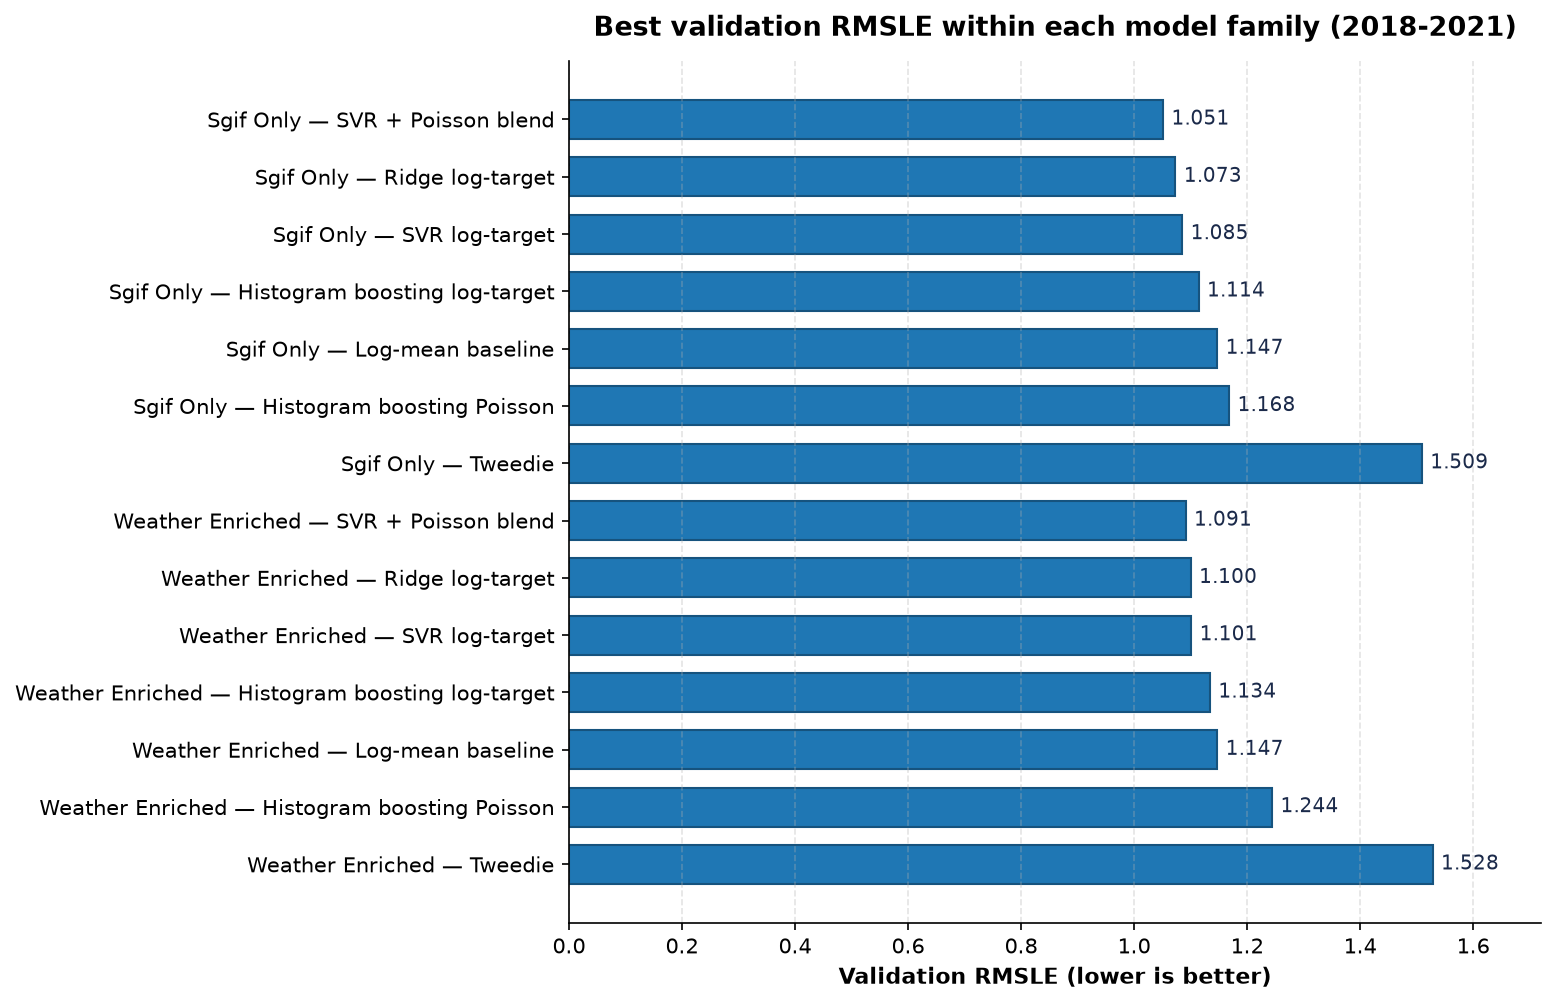

Saved figure: reports/figures/icnf_sgif/model_validation_family_rmsle.png


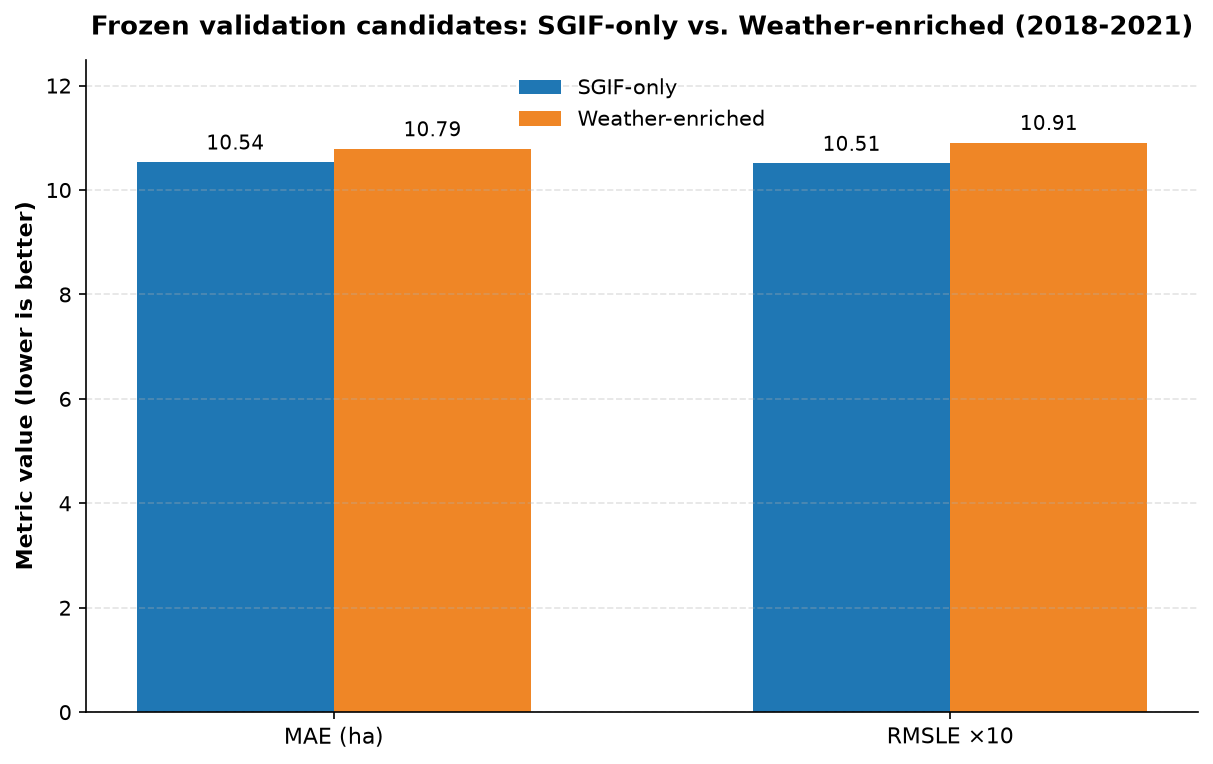

Saved figure: reports/figures/icnf_sgif/model_validation_selected_metrics.png


In [2]:
y_train_raw = unscaled_splits["train"]["target_area_ha"].to_numpy()
y_train_log = unscaled_splits["train"]["target_log1p_area"].to_numpy()
y_val_raw = unscaled_splits["validation"]["target_area_ha"].to_numpy()

sgif_cols = feature_sets_meta["sgif_only_features"]
weather_cols = feature_sets_meta["weather_enriched_features"]

X_train_sgif_scaled = scaled_splits["train"][sgif_cols].to_numpy()
X_val_sgif_scaled = scaled_splits["validation"][sgif_cols].to_numpy()
X_train_sgif_unscaled = unscaled_splits["train"][sgif_cols].to_numpy()
X_val_sgif_unscaled = unscaled_splits["validation"][sgif_cols].to_numpy()

# Demonstrate live scikit-learn training & validation evaluation across core families
log_mean_dummy = DummyRegressor(strategy="mean").fit(X_train_sgif_unscaled, y_train_log)
val_pred_log_mean = np.expm1(log_mean_dummy.predict(X_val_sgif_unscaled))

median_dummy = DummyRegressor(strategy="median").fit(X_train_sgif_unscaled, y_train_raw)
val_pred_median = median_dummy.predict(X_val_sgif_unscaled)

ridge_model = Ridge(alpha=100.0).fit(X_train_sgif_scaled, y_train_log)
val_pred_ridge = np.clip(np.expm1(ridge_model.predict(X_val_sgif_scaled)), 0.0, None)

tweedie_model = TweedieRegressor(power=1.9, alpha=0.1, max_iter=1000).fit(
    X_train_sgif_scaled, y_train_raw
)
val_pred_tweedie = np.clip(tweedie_model.predict(X_val_sgif_scaled), 0.0, None)

svr_model = SVR(kernel="rbf", C=1.0, epsilon=0.05, gamma=0.02).fit(
    X_train_sgif_scaled, y_train_log
)
val_pred_svr = np.clip(np.expm1(svr_model.predict(X_val_sgif_scaled)), 0.0, None)

hgb_poisson_model = HistGradientBoostingRegressor(
    loss="poisson",
    learning_rate=0.1,
    max_depth=8,
    min_samples_leaf=15,
    l2_regularization=10.0,
    max_iter=120,
    random_state=42,
).fit(X_train_sgif_unscaled, y_train_raw)
val_pred_poisson = np.clip(hgb_poisson_model.predict(X_val_sgif_unscaled), 0.0, None)

# Load comprehensive validation search tables & manifest
val_search_df = pd.read_csv(TABLES_DIR / "model_validation_search_results.csv")
val_family_best_df = pd.read_csv(TABLES_DIR / "model_validation_family_best.csv")
val_selected_df = pd.read_csv(TABLES_DIR / "model_validation_selected_candidates.csv")

with open(MODELS_DIR / "validation_selection_manifest.json", "r", encoding="utf-8") as f:
    val_manifest = json.load(f)

print(f"Total validation candidate configurations evaluated: {len(val_search_df)}")
print("Validation selection manifest summary:", val_manifest["selected_primary_candidate"], "vs.", val_manifest["selected_weather_candidate"])
print("\nBest validation model within each family (sorted by feature set and RMSLE):")
display(
    val_family_best_df[
        [
            "feature_set",
            "model_family",
            "parameters",
            "mae_ha",
            "rmse_ha",
            "median_ae_ha",
            "rmsle",
            "r2_log",
            "large_fire_mae_ha",
            "prediction_max_ha",
        ]
    ]
)

print("\nFrozen validation candidates selected for one-time final test evaluation:")
display(val_selected_df)

# Figure 1: Best validation RMSLE within each model family
plot_family_df = val_family_best_df[
    val_family_best_df["model_family"] != "Median baseline"
].copy()
plot_family_df["label"] = (
    plot_family_df["feature_set"].str.replace("_", " ").str.title()
    + " — "
    + plot_family_df["model_family"]
)
plot_family_df = plot_family_df.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10.5, 6.8))
bars = ax.barh(
    plot_family_df["label"],
    plot_family_df["rmsle"],
    color="#1f77b4",
    edgecolor="#16537e",
    height=0.68,
)
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.015,
        bar.get_y() + bar.get_height() / 2.0,
        f"{width:.3f}",
        va="center",
        ha="left",
        fontsize=9.5,
        color="#1b2a4a",
    )
ax.set_xlim(0.0, 1.72)
ax.set_xlabel("Validation RMSLE (lower is better)", fontsize=10.5, fontweight="bold")
ax.set_title(
    "Best validation RMSLE within each model family (2018-2021)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
fig1_path = FIGURES_DIR / "model_validation_family_rmsle.png"
plt.savefig(fig1_path, dpi=300)
plt.show()
print("Saved figure:", fig1_path.as_posix())

# Figure 2: Frozen validation candidates comparison (MAE and RMSLE x 10)
sgif_sel = val_selected_df[val_selected_df["feature_set"] == "sgif_only"].iloc[0]
wea_sel = val_selected_df[val_selected_df["feature_set"] == "weather_enriched"].iloc[0]

metric_labels = ["MAE (ha)", "RMSLE ×10"]
sgif_vals = [float(sgif_sel["mae_ha"]), float(sgif_sel["rmsle"]) * 10.0]
wea_vals = [float(wea_sel["mae_ha"]), float(wea_sel["rmsle"]) * 10.0]

x_pos = np.arange(len(metric_labels))
bar_w = 0.32

fig, ax = plt.subplots(figsize=(8.2, 5.2))
rects1 = ax.bar(
    x_pos - bar_w / 2.0, sgif_vals, bar_w, label="SGIF-only", color="#1f77b4"
)
rects2 = ax.bar(
    x_pos + bar_w / 2.0, wea_vals, bar_w, label="Weather-enriched", color="#ef8626"
)

for rect in list(rects1) + list(rects2):
    h = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2.0,
        h + 0.15,
        f"{h:.2f}",
        ha="center",
        va="bottom",
        fontsize=9.5,
    )

ax.set_xticks(x_pos)
ax.set_xticklabels(metric_labels, fontsize=10.5)
ax.set_ylabel("Metric value (lower is better)", fontsize=10.5, fontweight="bold")
ax.set_ylim(0.0, 12.5)
ax.set_title(
    "Frozen validation candidates: SGIF-only vs. Weather-enriched (2018-2021)",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
ax.legend(frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
fig2_path = FIGURES_DIR / "model_validation_selected_metrics.png"
plt.savefig(fig2_path, dpi=300)
plt.show()
print("Saved figure:", fig2_path.as_posix())


## 3. Supplementary Validation-Only Random Forest & Grouped Permutation Importance Audit

Validation-only Random Forest benchmark summary:


,feature_set,model_family,parameters,mae_ha,rmse_ha,median_ae_ha,rmsle,r2_log,large_fire_mae_ha,prediction_max_ha
0,sgif_only,Random Forest log-target (post-hoc validation audit),"{""max_depth"": 10, ""max_features"": 0.7, ""min_samples_leaf"": 15, ""n_estimators"": 400}",10.774,75.393,1.386,1.072,0.126,351.000,11.689
1,weather_enriched,Random Forest log-target (post-hoc validation audit),"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 15, ""n_estimators"": 400}",10.800,75.381,1.342,1.079,0.115,350.462,10.414



Validation grouped permutation importance (30 repeats, sorted by RMSLE increase):


,feature_group,features,rmsle_increase_mean,rmsle_increase_std,mae_increase_ha_mean
0,Map location,"x_etrs89_km, y_etrs89_km",0.074,0.020,0.284
1,Day of year,"doy_sin, doy_cos",0.041,0.021,0.127
2,Alert hour,"hour_sin, hour_cos",0.037,0.016,0.203
3,DC,DC,0.024,0.011,0.149
4,DMC,DMC,0.013,0.007,0.022
5,FFMC,FFMC,0.004,0.009,0.061
6,ISI,ISI,0.003,0.010,0.073
7,FWI,FWI,0.003,0.010,-0.004
8,Weekend,is_weekend,0.003,0.006,0.003
9,Municipality,municipality_vinhais,0.003,0.006,-0.014


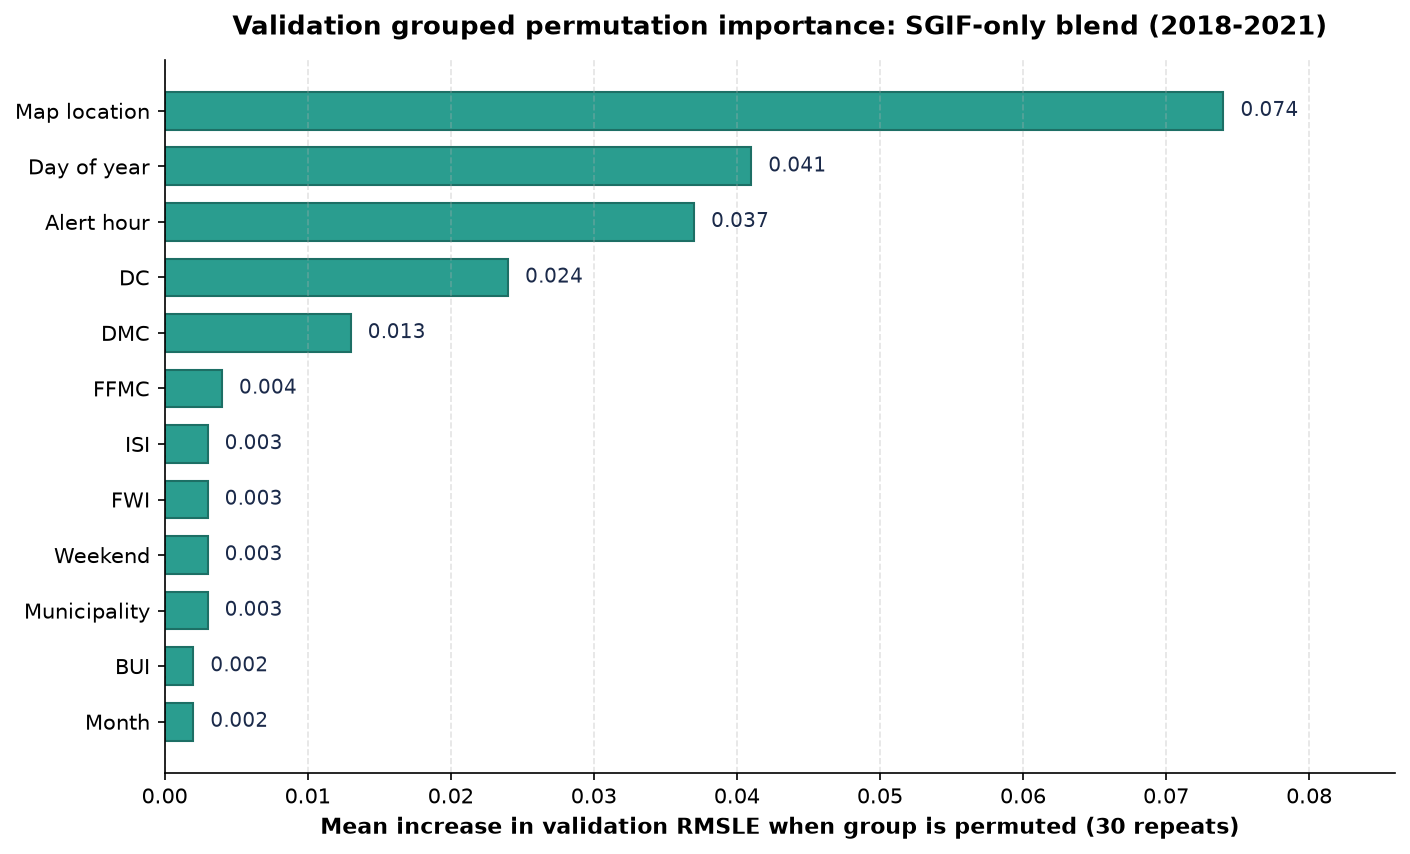

Saved figure: reports/figures/icnf_sgif/model_validation_feature_importance.png


In [3]:
# Demonstrate live RandomForestRegressor training on the log-transformed target
rf_sgif_model = RandomForestRegressor(
    n_estimators=400,
    max_depth=10,
    max_features=0.7,
    min_samples_leaf=15,
    random_state=42,
    n_jobs=-1,
).fit(X_train_sgif_unscaled, y_train_log)
val_pred_rf_sgif = np.clip(np.expm1(rf_sgif_model.predict(X_val_sgif_unscaled)), 0.0, None)

rf_best_df = pd.read_csv(TABLES_DIR / "model_validation_random_forest_best.csv")
perm_importance_df = pd.read_csv(
    TABLES_DIR / "model_validation_grouped_permutation_importance.csv"
)

with open(
    MODELS_DIR / "validation_only_rf_and_importance_manifest.json", "r", encoding="utf-8"
) as f:
    rf_manifest = json.load(f)

print("Validation-only Random Forest benchmark summary:")
display(
    rf_best_df[
        [
            "feature_set",
            "model_family",
            "parameters",
            "mae_ha",
            "rmse_ha",
            "median_ae_ha",
            "rmsle",
            "r2_log",
            "large_fire_mae_ha",
            "prediction_max_ha",
        ]
    ]
)

print("\nValidation grouped permutation importance (30 repeats, sorted by RMSLE increase):")
display(perm_importance_df)

# Figure 3: Grouped permutation importance on validation
plot_imp_df = perm_importance_df.iloc[::-1].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.5, 5.8))
bars = ax.barh(
    plot_imp_df["feature_group"],
    plot_imp_df["rmsle_increase_mean"],
    color="#2a9d8f",
    edgecolor="#1d6f65",
    height=0.68,
)
for bar in bars:
    w = bar.get_width()
    ax.text(
        w + 0.0012,
        bar.get_y() + bar.get_height() / 2.0,
        f"{w:.3f}",
        va="center",
        ha="left",
        fontsize=9.5,
        color="#1b2a4a",
    )
ax.set_xlim(0.0, 0.086)
ax.set_xlabel(
    "Mean increase in validation RMSLE when group is permuted (30 repeats)",
    fontsize=10.5,
    fontweight="bold",
)
ax.set_title(
    "Validation grouped permutation importance: SGIF-only blend (2018-2021)",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
fig3_path = FIGURES_DIR / "model_validation_feature_importance.png"
plt.savefig(fig3_path, dpi=300)
plt.show()
print("Saved figure:", fig3_path.as_posix())


## 4. One-Time Protected Final-Test Evaluation (`2022–2025`)

Live-computed test metrics for SGIF-only blend: {'mae_ha': 14.341, 'rmse_ha': 78.803, 'median_ae_ha': 1.511, 'rmsle': 1.181, 'bias_ha': -12.695, 'r2_raw': -0.008, 'r2_log': 0.143, 'large_fire_count': 5, 'large_fire_mae_ha': 388.596, 'prediction_min_ha': 0.023, 'prediction_median_ha': 1.801, 'prediction_mean_ha': 2.231, 'prediction_max_ha': 14.112}
Live-computed test metrics for Weather-enriched blend: {'mae_ha': 14.305, 'rmse_ha': 79.292, 'median_ae_ha': 1.503, 'rmsle': 1.189, 'bias_ha': -12.887, 'r2_raw': -0.021, 'r2_log': 0.131, 'large_fire_count': 5, 'large_fire_mae_ha': 390.541, 'prediction_min_ha': 0.061, 'prediction_median_ha': 1.715, 'prediction_mean_ha': 2.039, 'prediction_max_ha': 7.43}

Protected Final-Test Evaluation Summary (2022-2025, n = 187 fires):


,split,feature_set,model_family,candidate_id,selected_before_test,mae_ha,rmse_ha,median_ae_ha,rmsle,bias_ha,r2_raw,r2_log,large_fire_count,large_fire_mae_ha,prediction_min_ha,prediction_median_ha,prediction_mean_ha,prediction_max_ha
0,test,sgif_only,SVR + Poisson blend,sgif_only__blend__w0.8,True,14.341,78.803,1.511,1.181,-12.695,-0.008,0.143,5,388.596,0.023,1.801,2.231,14.112
1,test,weather_enriched,SVR + Poisson blend,weather_enriched__blend__w0.9,False,14.305,79.292,1.503,1.189,-12.887,-0.021,0.131,5,390.541,0.061,1.715,2.039,7.430
2,test,baseline,Log-mean baseline,baseline__log_mean,False,14.694,79.565,1.749,1.282,-13.077,-0.028,-0.010,5,390.733,1.849,1.849,1.849,1.849
3,test,baseline,Median baseline,baseline__median,False,14.630,79.709,0.970,1.363,-13.926,-0.031,-0.141,5,391.583,1.000,1.000,1.000,1.000


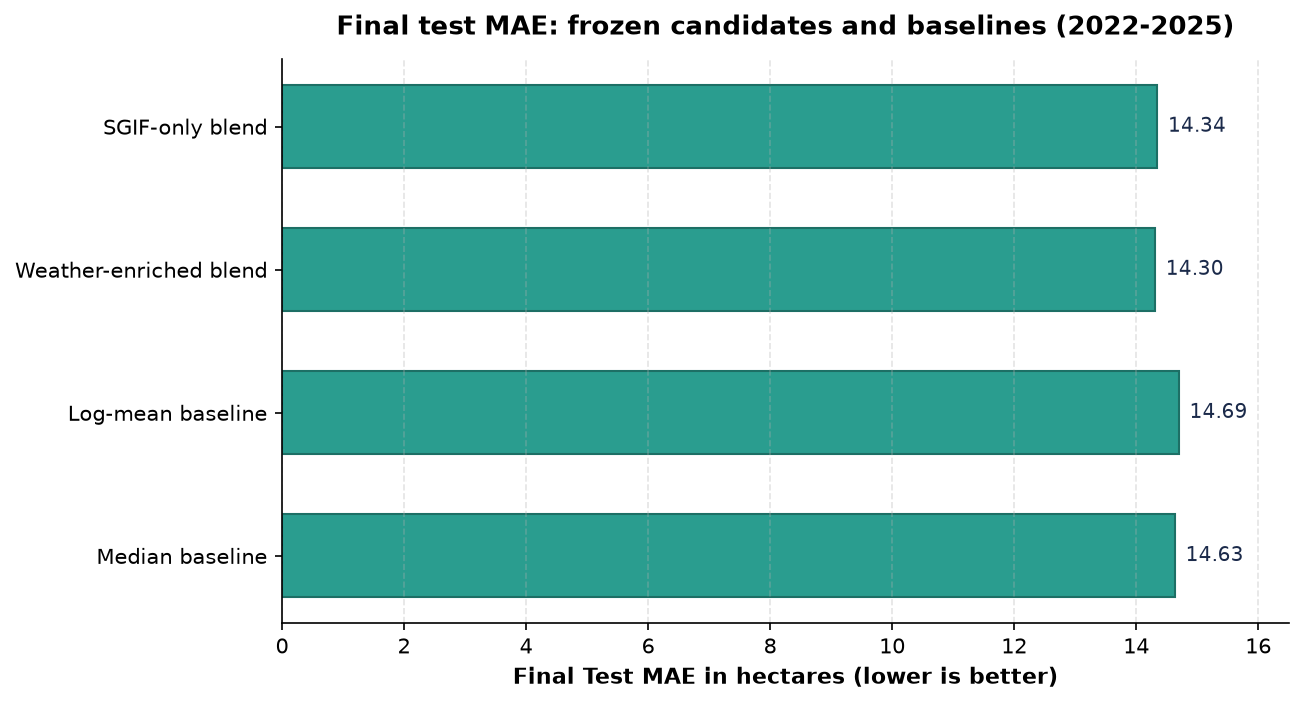

Saved figure: reports/figures/icnf_sgif/model_final_test_mae.png


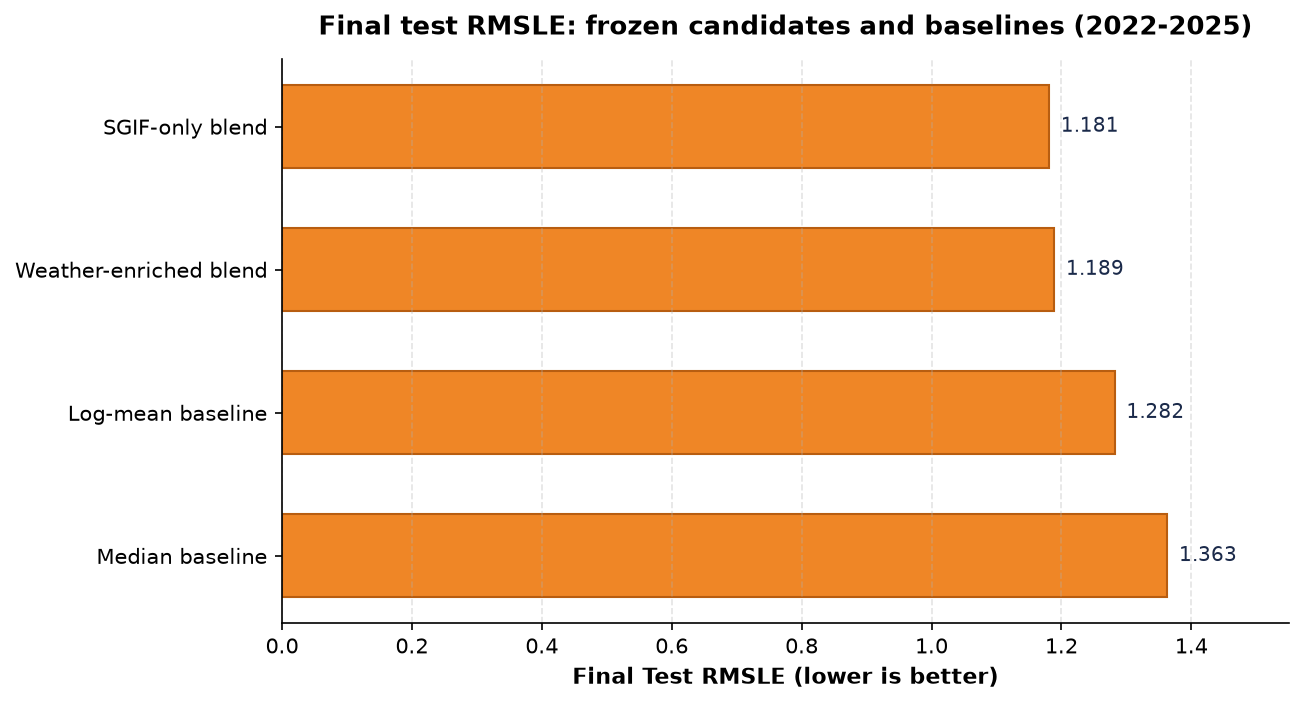

Saved figure: reports/figures/icnf_sgif/model_final_test_rmsle.png


In [4]:
test_preds_df = pd.read_csv(TABLES_DIR / "model_final_test_predictions.csv")
final_test_metrics_df = pd.read_csv(TABLES_DIR / "model_final_test_metrics.csv")

with open(MODELS_DIR / "final_test_evaluation_manifest.json", "r", encoding="utf-8") as f:
    test_manifest = json.load(f)

# Live verification of final test metrics using compute_evaluation_metrics()
y_test_actual = test_preds_df["target_area_ha"].to_numpy()
live_sgif_test_metrics = compute_evaluation_metrics(
    y_test_actual, test_preds_df["prediction_sgif_only_ha"].to_numpy()
)
live_weather_test_metrics = compute_evaluation_metrics(
    y_test_actual, test_preds_df["prediction_weather_enriched_ha"].to_numpy()
)

print("Live-computed test metrics for SGIF-only blend:", live_sgif_test_metrics)
print("Live-computed test metrics for Weather-enriched blend:", live_weather_test_metrics)
print("\nProtected Final-Test Evaluation Summary (2022-2025, n = 187 fires):")
display(final_test_metrics_df)

# Prepare labels for horizontal bar charts
chart_labels = [
    "SGIF-only blend",
    "Weather-enriched blend",
    "Log-mean baseline",
    "Median baseline",
][::-1]
mae_values = final_test_metrics_df["mae_ha"].tolist()[::-1]
rmsle_values = final_test_metrics_df["rmsle"].tolist()[::-1]

# Figure 4: Final test MAE
fig, ax = plt.subplots(figsize=(8.8, 4.8))
bars = ax.barh(
    chart_labels, mae_values, color="#2a9d8f", edgecolor="#1d6f65", height=0.58
)
for bar in bars:
    w = bar.get_width()
    ax.text(
        w + 0.18,
        bar.get_y() + bar.get_height() / 2.0,
        f"{w:.2f}",
        va="center",
        ha="left",
        fontsize=9.5,
        color="#1b2a4a",
    )
ax.set_xlim(0.0, 16.5)
ax.set_xlabel("Final Test MAE in hectares (lower is better)", fontsize=10.5, fontweight="bold")
ax.set_title(
    "Final test MAE: frozen candidates and baselines (2022-2025)",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
fig4_path = FIGURES_DIR / "model_final_test_mae.png"
plt.savefig(fig4_path, dpi=300)
plt.show()
print("Saved figure:", fig4_path.as_posix())

# Figure 5: Final test RMSLE
fig, ax = plt.subplots(figsize=(8.8, 4.8))
bars = ax.barh(
    chart_labels, rmsle_values, color="#ef8626", edgecolor="#b85d10", height=0.58
)
for bar in bars:
    w = bar.get_width()
    ax.text(
        w + 0.018,
        bar.get_y() + bar.get_height() / 2.0,
        f"{w:.3f}",
        va="center",
        ha="left",
        fontsize=9.5,
        color="#1b2a4a",
    )
ax.set_xlim(0.0, 1.55)
ax.set_xlabel("Final Test RMSLE (lower is better)", fontsize=10.5, fontweight="bold")
ax.set_title(
    "Final test RMSLE: frozen candidates and baselines (2022-2025)",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
fig5_path = FIGURES_DIR / "model_final_test_rmsle.png"
plt.savefig(fig5_path, dpi=300)
plt.show()
print("Saved figure:", fig5_path.as_posix())


## 5. Prediction Behavior by Fire Size & Extreme-Fire Underprediction Analysis


Final test error decomposed by actual wildfire size group (2022-2025):


,feature_set,fire_size_group,records,actual_mean_ha,prediction_mean_ha,mae_ha,median_ae_ha,rmsle
0,sgif_only,0 to <1 ha,90,0.269,1.647,1.380,1.143,0.792
1,sgif_only,1 to <10 ha,67,3.609,2.490,2.010,1.530,0.607
2,sgif_only,10 to <100 ha,25,22.492,3.292,19.200,15.012,1.691
3,sgif_only,>=100 ha,5,392.583,3.987,388.596,248.395,4.650
4,weather_enriched,0 to <1 ha,90,0.269,1.472,1.203,1.054,0.728
5,weather_enriched,1 to <10 ha,67,3.609,2.225,2.110,1.746,0.682
6,weather_enriched,10 to <100 ha,25,22.492,3.584,18.908,14.493,1.622
7,weather_enriched,>=100 ha,5,392.583,2.042,390.541,247.760,4.894



Cross-split validation and protected test performance summary:


,Evaluation Split,Candidate Model,Feature Count,MAE (ha),RMSE (ha),Median AE (ha),RMSLE,R2 (log),Large-Fire MAE >=100 ha (ha),Max Prediction (ha)
0,Validation (2018-2021),SGIF-only SVR + Poisson blend (80% / 20%),18,10.535,75.372,1.260,1.051,0.160,349.801,30.462
1,Validation (2018-2021),Weather-enriched SVR + Poisson blend (90% / 10%),23,10.789,75.395,1.257,1.091,0.095,349.180,11.943
2,Protected Test (2022-2025),SGIF-only SVR + Poisson blend (Recommended),18,14.341,78.803,1.511,1.181,0.143,388.596,14.112
3,Protected Test (2022-2025),Weather-enriched SVR + Poisson blend,23,14.305,79.292,1.503,1.189,0.131,390.541,7.430



Largest test-set wildfires (>= 100 ha) and model predictions:


,Codigo_SGIF,Ano,Mes,alert_time_local,target_area_ha,prediction_sgif_only_ha,prediction_weather_enriched_ha
4,2022_04_0002704,2022,1,2022-01-28 08:00:00,924.495,14.112,6.553
116,20240986285,2024,8,2024-08-10 18:54:00,445.180,0.794,0.186
150,20250974143,2025,7,2025-07-25 12:07:00,248.544,0.148,0.784
49,2022_04_0021762,2022,7,2022-07-15 07:07:00,198.240,1.368,1.712
162,20251078764,2025,8,2025-08-13 15:25:00,146.456,3.512,0.975


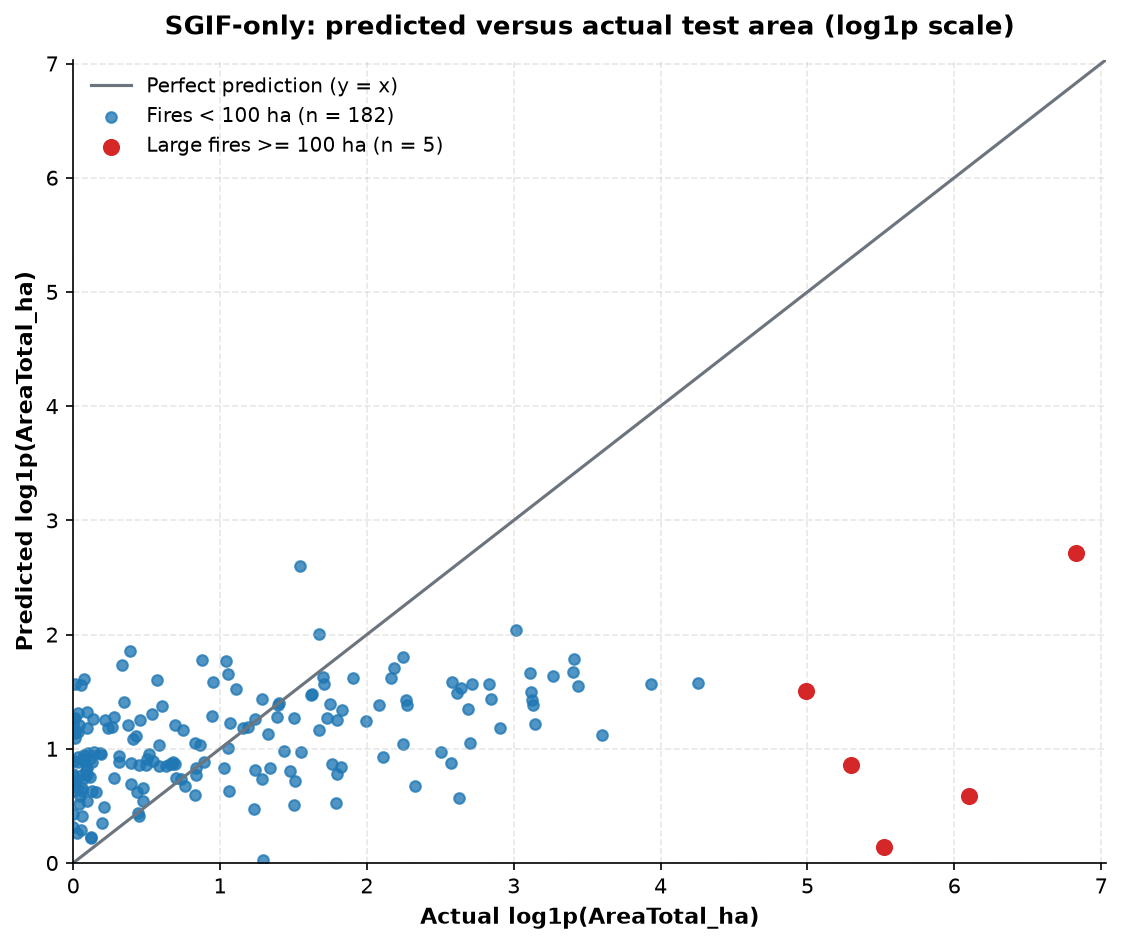

Saved figure: reports/figures/icnf_sgif/model_test_scatter_sgif_only.png


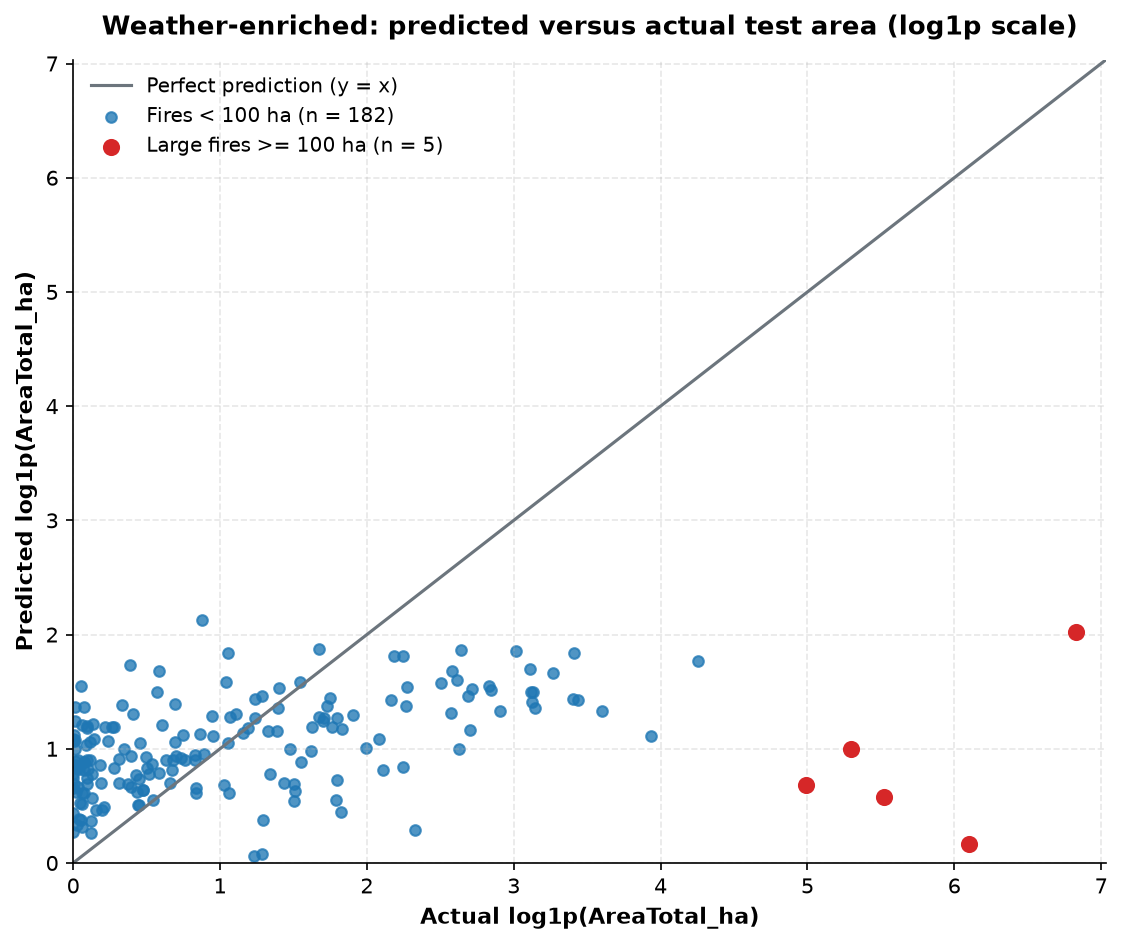

Saved figure: reports/figures/icnf_sgif/model_test_scatter_weather.png


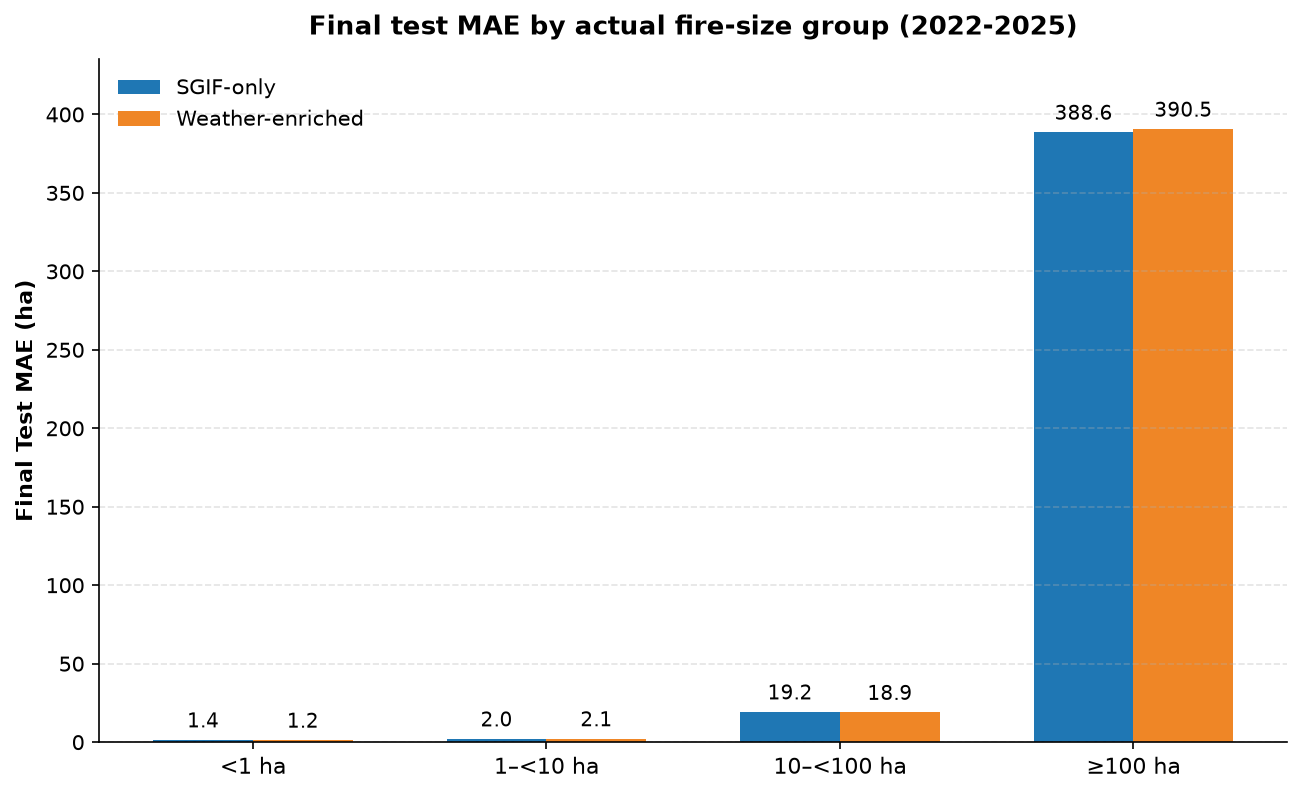

Saved figure: reports/figures/icnf_sgif/model_test_mae_by_fire_size.png


In [5]:
size_error_df = pd.read_csv(TABLES_DIR / "model_test_error_by_fire_size.csv")
report_perf_df = pd.read_csv(TABLES_DIR / "report_model_performance_summary.csv")

print("Final test error decomposed by actual wildfire size group (2022-2025):")
display(size_error_df)

print("\nCross-split validation and protected test performance summary:")
display(report_perf_df)

print("\nLargest test-set wildfires (>= 100 ha) and model predictions:")
large_test_fires = test_preds_df[test_preds_df["target_area_ha"] >= 100.0].sort_values(
    "target_area_ha", ascending=False
)
display(
    large_test_fires[
        [
            "Codigo_SGIF",
            "Ano",
            "Mes",
            "alert_time_local",
            "target_area_ha",
            "prediction_sgif_only_ha",
            "prediction_weather_enriched_ha",
        ]
    ]
)

# Figures 6 & 7: Predicted vs. actual test area in log1p space (SGIF-only and Weather-enriched)
actual_log = np.log1p(test_preds_df["target_area_ha"].to_numpy())
is_large = test_preds_df["target_area_ha"].to_numpy() >= 100.0

for pred_col, title_str, fig_name in [
    (
        "prediction_sgif_only_ha",
        "SGIF-only: predicted versus actual test area (log1p scale)",
        "model_test_scatter_sgif_only.png",
    ),
    (
        "prediction_weather_enriched_ha",
        "Weather-enriched: predicted versus actual test area (log1p scale)",
        "model_test_scatter_weather.png",
    ),
]:
    pred_log = np.log1p(test_preds_df[pred_col].to_numpy())
    max_axis = float(max(actual_log.max(), pred_log.max()) * 1.03)

    fig, ax = plt.subplots(figsize=(7.6, 6.4))
    ax.plot(
        [0.0, max_axis],
        [0.0, max_axis],
        color="#6c757d",
        linestyle="-",
        linewidth=1.5,
        label="Perfect prediction (y = x)",
    )
    ax.scatter(
        actual_log[~is_large],
        pred_log[~is_large],
        color="#1f77b4",
        alpha=0.78,
        s=26,
        label="Fires < 100 ha (n = 182)",
    )
    ax.scatter(
        actual_log[is_large],
        pred_log[is_large],
        color="#d62728",
        s=52,
         zorder=5,
        label="Large fires >= 100 ha (n = 5)",
    )
    ax.set_xlim(0.0, max_axis)
    ax.set_ylim(0.0, max_axis)
    ax.set_xlabel("Actual log1p(AreaTotal_ha)", fontsize=10.5, fontweight="bold")
    ax.set_ylabel("Predicted log1p(AreaTotal_ha)", fontsize=10.5, fontweight="bold")
    ax.set_title(title_str, fontsize=12.5, fontweight="bold", pad=12)
    ax.legend(frameon=False, loc="upper left", fontsize=9.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid( linestyle="--", alpha=0.3)
    plt.tight_layout()
    scatter_path = FIGURES_DIR / fig_name
    plt.savefig(scatter_path, dpi=300)
    plt.show()
    print("Saved figure:", scatter_path.as_posix())

# Figure 8: Final test MAE by actual fire-size group
sgif_size = size_error_df[size_error_df["feature_set"] == "sgif_only"]
wea_size = size_error_df[size_error_df["feature_set"] == "weather_enriched"]

group_labels = ["<1 ha", "1–<10 ha", "10–<100 ha", "≥100 ha"]
sgif_group_mae = sgif_size["mae_ha"].tolist()
wea_group_mae = wea_size["mae_ha"].tolist()

x_idx = np.arange(len(group_labels))
width = 0.34

fig, ax = plt.subplots(figsize=(8.8, 5.4))
b1 = ax.bar(
    x_idx - width / 2.0, sgif_group_mae, width, label="SGIF-only", color="#1f77b4"
)
b2 = ax.bar(
    x_idx + width / 2.0,
    wea_group_mae,
    width,
    label="Weather-enriched",
    color="#ef8626",
)

for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        h + 5.0,
        f"{h:.1f}",
        ha="center",
        va="bottom",
        fontsize=9.5,
    )

ax.set_xticks(x_idx)
ax.set_xticklabels(group_labels, fontsize=10.5)
ax.set_ylabel("Final Test MAE (ha)", fontsize=10.5, fontweight="bold")
ax.set_ylim(0.0, 435.0)
ax.set_title(
    "Final test MAE by actual fire-size group (2022-2025)",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
ax.legend(frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
fig8_path = FIGURES_DIR / "model_test_mae_by_fire_size.png"
plt.savefig(fig8_path, dpi=300)
plt.show()
print("Saved figure:", fig8_path.as_posix())


## 6. Serializing & Verifying Deployment Model Bundles (`models/`)

In [6]:
saved_verification_df = pd.read_csv(TABLES_DIR / "saved_model_verification.csv")

loaded_bundles_info = []
for artifact_rel in [
    "models/sgif_only_final_blend.joblib",
    "models/weather_enriched_final_blend.joblib",
    "models/final_recommended_model.joblib",
]:
    bundle = joblib.load(Path(artifact_rel))
    loaded_bundles_info.append(
        {
            "artifact_file": artifact_rel,
            "bundle_name": bundle["bundle_name"],
            "feature_set": bundle["feature_set"],
            "n_features": len(bundle["features"]),
            "svr_estimator": type(bundle["svr_model"]).__name__,
            "poisson_estimator": type(bundle["poisson_model"]).__name__,
            "svr_weight": bundle["weights"]["svr_log"],
            "poisson_weight": bundle["weights"]["poisson_raw"],
            "val_rmsle": bundle["validation_metrics"]["rmsle"],
            "test_rmsle": bundle["test_metrics"]["rmsle"],
            "test_mae_ha": bundle["test_metrics"]["mae_ha"],
        }
    )

loaded_bundles_df = pd.DataFrame(loaded_bundles_info)
print("Reloaded .joblib deployment bundles verification:")
display(loaded_bundles_df)

print("\nSaved model verification table (reports/tables/icnf_sgif/saved_model_verification.csv):")
display(saved_verification_df)


Reloaded .joblib deployment bundles verification:


,artifact_file,bundle_name,feature_set,n_features,svr_estimator,poisson_estimator,svr_weight,poisson_weight,val_rmsle,test_rmsle,test_mae_ha
0,models/sgif_only_final_blend.joblib,sgif_only_final_blend,sgif_only,18,SVR,HistGradientBoostingRegressor,0.8,0.2,1.074,1.181,14.341
1,models/weather_enriched_final_blend.joblib,weather_enriched_final_blend,weather_enriched,23,SVR,HistGradientBoostingRegressor,0.9,0.1,1.096,1.189,14.305
2,models/final_recommended_model.joblib,sgif_only_final_blend,sgif_only,18,SVR,HistGradientBoostingRegressor,0.8,0.2,1.074,1.181,14.341



Saved model verification table (reports/tables/icnf_sgif/saved_model_verification.csv):


,artifact_file,feature_set,feature_count,svr_weight,poisson_weight,validation_rmsle,test_rmsle,test_mae_ha
0,models/sgif_only_final_blend.joblib,sgif_only,18,0.8,0.2,1.051,1.181,14.341
1,models/weather_enriched_final_blend.joblib,weather_enriched,23,0.9,0.1,1.091,1.189,14.305
2,models/final_recommended_model.joblib,sgif_only,18,0.8,0.2,1.051,1.181,14.341


## 7. Formal Dataset & Model Decision Gate: Official ICNF SGIF Cohort vs. Legacy UCI Benchmark

In [7]:
uci_df = pd.read_csv(UCI_CLEANED_PATH)
uci_area = uci_df["area"]

sgif_all_area = pd.concat(
    [
        unscaled_splits["train"]["target_area_ha"],
        unscaled_splits["validation"]["target_area_ha"],
        unscaled_splits["test"]["target_area_ha"],
    ],
    ignore_index=True,
)

cohort_comparison_df = pd.DataFrame(
    [
        {
            "Dataset Cohort": "Legacy UCI Benchmark (2000-2003, cleaned)",
            "Cleaned Records": len(uci_df),
            "Zero-Area Records": int((uci_area == 0).sum()),
            "Zero-Area Share (%)": round(float((uci_area == 0).mean() * 100.0), 2),
            "Median Area (ha)": round(float(uci_area.median()), 3),
            "Mean Area (ha)": round(float(uci_area.mean()), 3),
            "Max Area (ha)": round(float(uci_area.max()), 2),
            "Large Fires >= 100 ha": int((uci_area >= 100.0).sum()),
        },
        {
            "Dataset Cohort": "Official ICNF SGIF Montesinho Cohort (2004-2025)",
            "Cleaned Records": len(sgif_all_area),
            "Zero-Area Records": int((sgif_all_area == 0).sum()),
            "Zero-Area Share (%)": round(float((sgif_all_area == 0).mean() * 100.0), 2),
            "Median Area (ha)": round(float(sgif_all_area.median()), 3),
            "Mean Area (ha)": round(float(sgif_all_area.mean()), 3),
            "Max Area (ha)": round(float(sgif_all_area.max()), 2),
            "Large Fires >= 100 ha": int((sgif_all_area >= 100.0).sum()),
        },
    ]
)

amendment_summary_df = pd.read_csv(TABLES_DIR / "report_dataset_amendment_summary.csv")
project_decision_df = pd.read_csv(TABLES_DIR / "project_dataset_model_decision.csv")

print("Direct empirical comparison: Legacy UCI benchmark vs. Official ICNF SGIF cohort:")
display(cohort_comparison_df)

print("\nDataset amendment summary (reports/tables/icnf_sgif/report_dataset_amendment_summary.csv):")
display(amendment_summary_df)

print("\nProject dataset and model decision log (reports/tables/icnf_sgif/project_dataset_model_decision.csv):")
display(project_decision_df)


Direct empirical comparison: Legacy UCI benchmark vs. Official ICNF SGIF cohort:


,Dataset Cohort,Cleaned Records,Zero-Area Records,Zero-Area Share (%),Median Area (ha),Mean Area (ha),Max Area (ha),Large Fires >= 100 ha
0,"Legacy UCI Benchmark (2000-2003, cleaned)",513,244,47.56,0.54,12.892,1090.84,11
1,Official ICNF SGIF Montesinho Cohort (2004-2025),1644,19,1.16,1.00,9.856,1057.50,31



Dataset amendment summary (reports/tables/icnf_sgif/report_dataset_amendment_summary.csv):


,Dimension,"Original UCI Benchmark (Cortez & Morais, 2007)",Amended Official ICNF SGIF Cohort
0,Primary data source,Legacy UCI Forest Fires CSV (2000-2003),Official ICNF SGIF registry + PN Montesinho boundary + NASA POWER
1,Temporal coverage,January 2000 to December 2003 (4 years),2004 to 2025 (22 years; chronological Train/Val/Test split)
2,Cleaned sample size,513 records (after removing 4 exact duplicates from 517),"1,644 official-boundary records (Train: 1,250 | Val: 207 | Test: 187)"
3,Zero burned-area share,244 zero-area rows (47.56% of cleaned dataset),19 recorded zero-area micro-fires (1.16% of official cohort)
4,Large wildfire events (>= 100 ha),"11 events (max 1,090.84 ha)","31 events (max 1,057.50 ha; 22 Train / 4 Val / 5 Test)"
5,Spatial localization,"Coarse 9x9 grid indices (X, Y from 1 to 9)",Exact ETRS89 / PT-TM06 kilometric coordinates + Bragança/Vinhais flag
6,Temporal predictors,Categorical month and day-of-week strings only,"Cyclical month, day-of-year, and alert-hour sine/cosine + weekend flag"
7,Meteorological & FWI features,"4 FWI indices (FFMC, DMC, DC, ISI) + 4 station weather vars","All 7 FWI components (FFMC, DMC, DC, ISI, BUI, FWI, DSR) + causal NASA POWER"
8,Out-of-sample predictive signal,No model beat constant baselines (Repeated-CV MAE 11.62 vs 11.73 ha),SGIF-only blend beats baselines on Val (RMSLE 1.051 vs 1.147) & Test (1.181 vs 1.282)



Project dataset and model decision log (reports/tables/icnf_sgif/project_dataset_model_decision.csv):


,Decision Gate,Evidence Summary,Outcome
0,1. Legacy UCI Repeated-CV Benchmark,Repeated-CV mean MAE 11.62 ha versus 11.73 ha for the best learned model; log-target models remained near zero or negative R2.,Retained as historical baseline evidence in 02_ORIGINAL_UCI_EVIDENCE/
1,2. Legacy UCI Fixed-Test Benchmark,"Fixed-test MAE 17.30 ha; RMSE 111.20 ha; median AE 1.45 ha; maximum absolute error 1089.90 ha on the 1,090.84 ha outlier.",Justified amending primary dataset to official 2004-2025 ICNF SGIF registry
2,3. Chronological Validation Model Selection (2018-2021),"SGIF-only SVR + Poisson blend achieved RMSLE 1.051 and MAE 10.535 ha, beating Weather-enriched blend (RMSLE 1.091, MAE 10.789 ha) and Log-mean baseline (RMSLE 1.147).",Selected SGIF-only 80% SVR / 20% Poisson blend before final test
3,4. Supplementary Validation Random Forest & Importance Audit,"Validation Random Forest achieved RMSLE 1.072 (SGIF-only) and 1.079 (Weather-enriched); grouped permutation importance led by Map location (0.074), Day of year (0.041), Alert hour (0.037), DC (0.024), and DMC (0.013).",Confirmed spatial/seasonal/drought signal without reopening test selection
4,5. Protected Final-Test Evaluation (2022-2025),"SGIF-only blend achieved Test RMSLE 1.181, RMSE 78.803 ha, R2_log 0.143, and MAE 14.341 ha, outperforming Weather-enriched blend on RMSLE (1.189) and RMSE (79.292 ha) and beating both constant baselines.",Frozen in models/final_recommended_model.joblib as primary deployment model
